In [1]:
import numpy as np
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from pulse_vqe_entanglement.dataclasses import SimulationConfig
from pulse_vqe_entanglement.sqe_optimisation import sqe_optimisation
from pulse_vqe_entanglement.plotting import plot_sqe_optimisation

Tracing control amplitude graph.
[outer 00] I=4.018e-05, lam=4.028e+01, inner_nit=290, inner_success=True
[outer 01] I=9.997e-10, lam=4.028e+01, inner_nit=9, inner_success=True
[outer 02] I=1.229e-09, lam=4.028e+01, inner_nit=1, inner_success=True
[outer 03] I=1.188e-09, lam=4.028e+01, inner_nit=7, inner_success=True
[outer 04] I=7.513e-10, lam=4.028e+01, inner_nit=7, inner_success=True


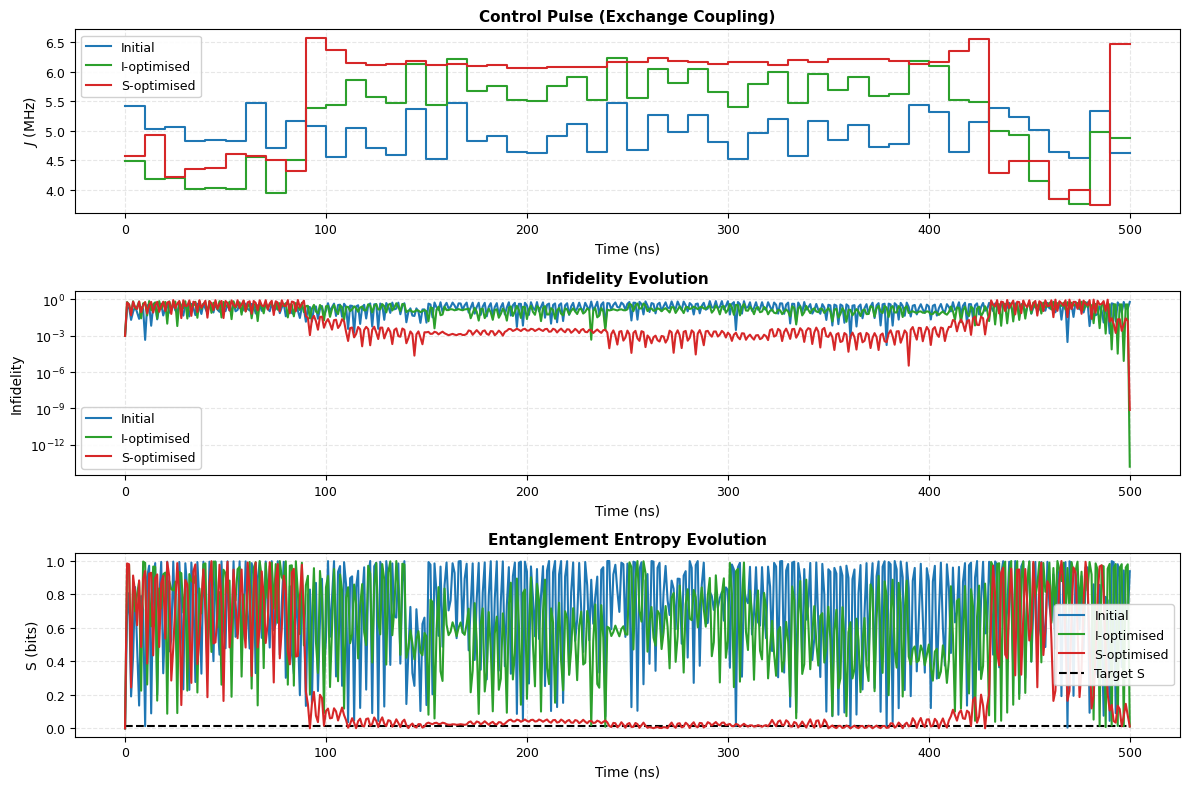

In [27]:
config = SimulationConfig(
    zeeman_splittings=np.array([0.0, 8.0]),
    initial_state=np.array([0.0, 1.0, 0.0, 0.0], dtype=np.complex128),
    theta_target=0.01 * np.pi,
    n_time_steps=50,
    n_discretisation=10,
    T=500.0,
    max_drive_strength=0.0,
    J_max=10.0,
    J_min=0.0,
    J_init_scale=1e-1,
    feromagnetic=False,
    gtol=1e-12,
    maxiter=200,

    # run both with identical x0
    run_mode="both",
    init_seed=None,

    # primal-dual settings
    S_max=0.05,
    eps_infidelity=1e-12,
    rho=10.0,
    dual_lr=1e6,
    n_outer=5,
    inner_maxiter=300,
    fd_eps=1e-5,
)

results = sqe_optimisation(config)
plot_sqe_optimisation(results)
